# Ahmedabad Tiffin Service – Sales Analysis
## Seaborn Session 2 – Categorical Visuals

Analysis of 300 fictional tiffin orders using Seaborn countplots and barplots.

Task 1: Generate 300 orders

   order_id       area meal_type plan_type  quantity  amount_inr
0         1  Naranpura      Diet    Weekly         1         140
1         2  Vastrapur       Veg   Monthly         2         180
2         3  Maninagar      Jain   Monthly         4         400
3         4  Vastrapur      Jain    Weekly         4         400
4         5  Vastrapur      Diet    Weekly         3         420
Total Orders: 300


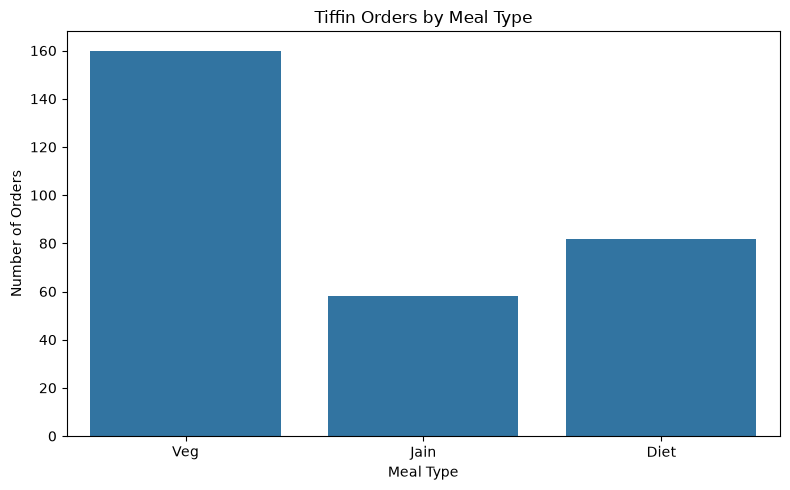

In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

order_id = np.arange(1, 301)

area = np.random.choice(
    ["Satellite", "Bopal", "Maninagar", "Naranpura", "Vastrapur"],
    size=300
)

meal_type = np.random.choice(
    ["Veg", "Jain", "Diet"],
    size=300,
    p=[0.5, 0.2, 0.3]
)

plan_type = np.random.choice(
    ["Trial", "Weekly", "Monthly"],
    size=300
)

quantity = np.random.randint(1, 5, size=300)

rate = np.where(
    meal_type == "Veg", 90,
    np.where(meal_type == "Jain", 100, 140)
)

amount_inr = quantity * rate

df = pd.DataFrame({
    "order_id": order_id,
    "area": area,
    "meal_type": meal_type,
    "plan_type": plan_type,
    "quantity": quantity,
    "amount_inr": amount_inr
})

df.to_csv("tiffin_orders.csv", index=False)

print(df.head())
print("Total Orders:", len(df))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="meal_type",
    order=["Veg", "Jain", "Diet"]
)

plt.title("Tiffin Orders by Meal Type")
plt.xlabel("Meal Type")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


Task 2: Orders by area and plan type

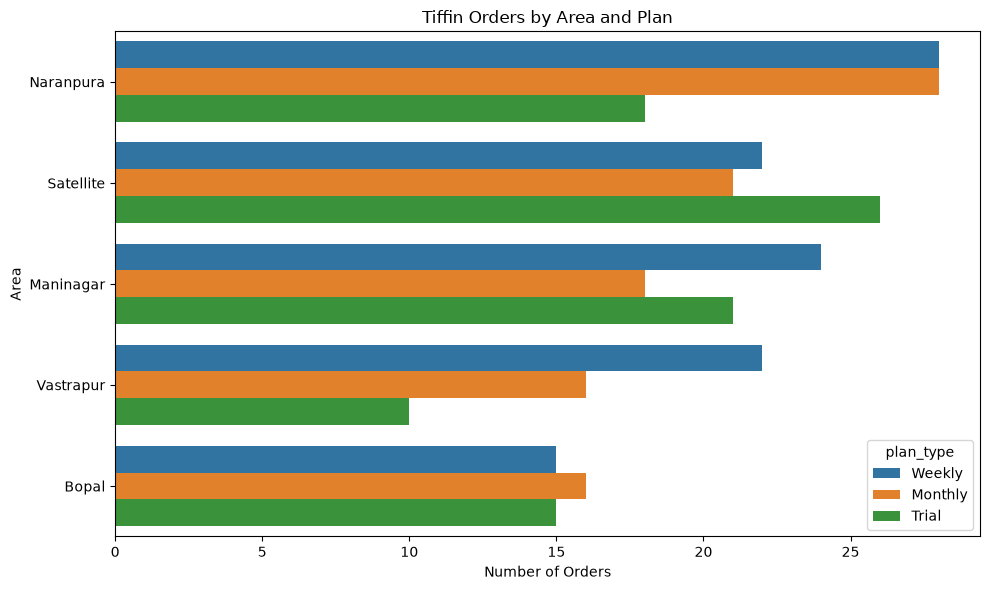

Area chart saved successfully!


In [2]:

area_order = df["area"].value_counts().index

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="area",
    hue="plan_type",
    order=area_order
)

plt.title("Tiffin Orders by Area and Plan")
plt.xlabel("Number of Orders")
plt.ylabel("Area")

plt.tight_layout()
plt.savefig("tiffin_area_plans.png", dpi=150)
plt.show()

print("Area chart saved successfully!")


Task 3: Mean vs total revenue

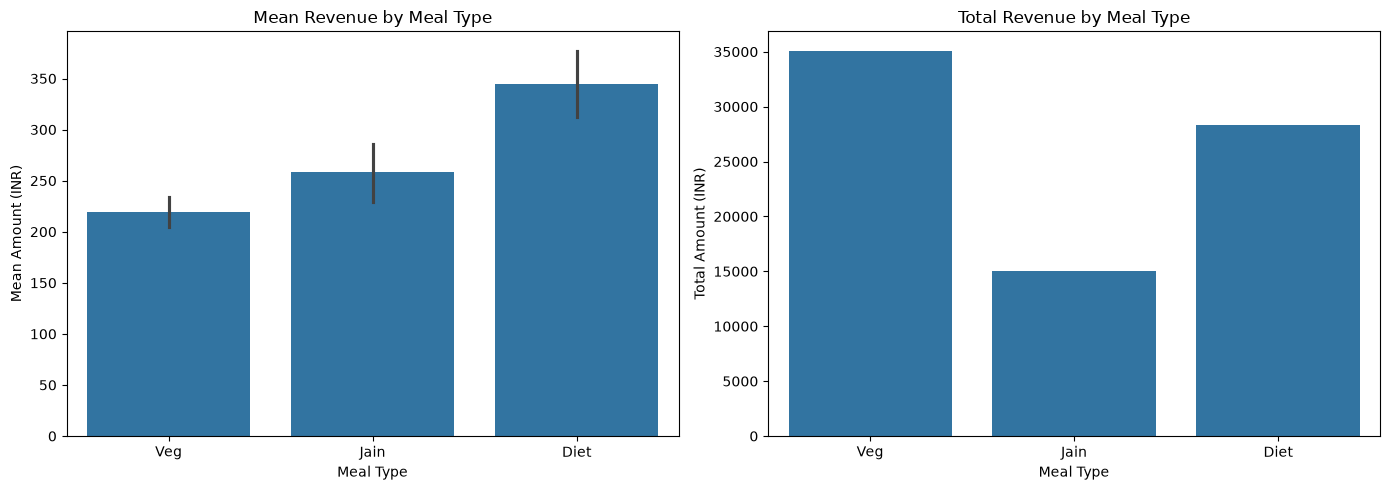

Mean vs Sum chart saved!


In [3]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df,
    x="meal_type",
    y="amount_inr",
    order=["Veg", "Jain", "Diet"],
    estimator="mean",
    ax=axes[0]
)

axes[0].set_title("Mean Revenue by Meal Type")
axes[0].set_xlabel("Meal Type")
axes[0].set_ylabel("Mean Amount (INR)")

sns.barplot(
    data=df,
    x="meal_type",
    y="amount_inr",
    order=["Veg", "Jain", "Diet"],
    estimator="sum",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Total Revenue by Meal Type")
axes[1].set_xlabel("Meal Type")
axes[1].set_ylabel("Total Amount (INR)")

plt.tight_layout()
plt.savefig("tiffin_mean_vs_sum.png", dpi=150)
plt.show()

print("Mean vs Sum chart saved!")


Task 4: Total revenue by area

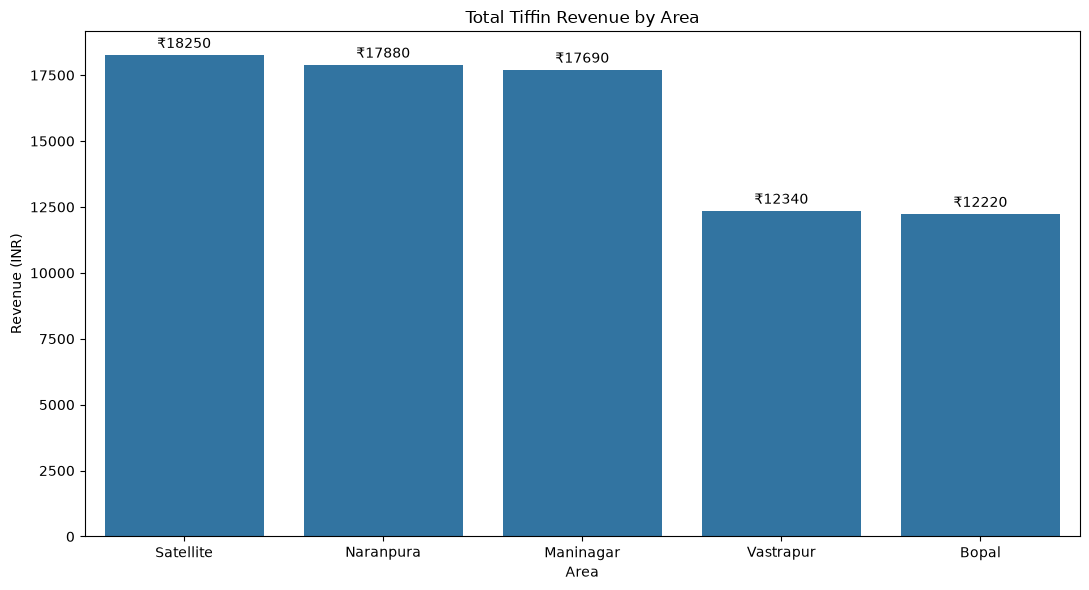

Revenue chart saved successfully!


In [4]:

revenue_order = (
    df.groupby("area")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=df,
    x="area",
    y="amount_inr",
    order=revenue_order,
    estimator="sum",
    errorbar=None,
    ax=ax
)

ax.set_title("Total Tiffin Revenue by Area")
ax.set_xlabel("Area")
ax.set_ylabel("Revenue (INR)")

ax.bar_label(
    ax.containers[0],
    fmt="₹%.0f",
    padding=3
)

plt.tight_layout()
plt.savefig("tiffin_revenue_by_area.png", dpi=150)
plt.show()

print("Revenue chart saved successfully!")
